# ID21636 — real R+C prediction test

Run All to inspect the completed experiment. To repeat it, set `RUN_NEW_FIT = True` below and Run All. Select the **grism** Python environment.

We fit **six R + six C exposures**, then predict **three withheld R + three withheld C exposures**. One flexible gas map and one rotation field are shared by both grisms; intrinsic dispersion is zero. This notebook examines optimized solutions and predictions. **It does not run MCMC or produce corner plots/error bars.**

This experiment is currently prepared for **ID21636**. The original rotation-only notebook is separate.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import importlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Find the repository even when Jupyter starts in your home directory.
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents,
    Path("/home/aakavan/kinematics/grism-kinematics")]
    if (p / "dingo" / "holdout_review.py").exists()), None)
if REPO is None:
    raise FileNotFoundError("Open this notebook in the grism-kinematics repository.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from dingo import holdout_review, holdout_workflow
importlib.reload(holdout_review)
importlib.reload(holdout_workflow)

RUN_NEW_FIT = False  # False: show the existing result. True: repeat the four-start experiment.
SAVED_RESULTS = Path("/home/aakavan/kinematics/working/ID21636_validation_2026-10-21/results.npz")
WORKING_DIR = Path("/home/aakavan/kinematics/working/validation")  # Change this for NEW runs.
CACHE_ROOT = REPO.parent / "results" / "real_sources" / "ID21636"
SOURCE_RUN = CACHE_ROOT / "morphology_controls_v1"
FIT_PYTHON = Path("/home/aakavan/anaconda3/envs/grism/bin/python")
MAXITER = 1600
REFINE = 2400

# Select the 1st, 2nd, or 3rd withheld exposure of each grism.
R_EXPOSURE = 1
C_EXPOSURE = 1
HALF_WIDTH = 20       # Detector pixels around the nominal line position; None shows the full cutout.
RESIDUAL_LIMIT = 5.0  # Symmetric color scale for residual / ERR.
SHOW_ALL_EXPOSURES = False

def show(fig):
    display(fig)
    plt.close(fig)

print("Saved result:", SAVED_RESULTS)
print("New run outputs:", WORKING_DIR / "ID21636", "(a new timestamped folder per run)")

Saved result: /home/aakavan/kinematics/working/ID21636_validation_2026-10-21/results.npz
New run outputs: /home/aakavan/kinematics/working/validation/ID21636 (a new timestamped folder per run)


## 1. Open or rerun the experiment

A new run shows progress and writes a log. Each rerun gets a new directory, so the reference result stays available. Interrupting this cell stops its worker. The previous GPU training test took about 13 seconds; preparation, assessment and plot export add time.

To reopen a new run later, set `SAVED_RESULTS` to its printed `results.npz` path and set `RUN_NEW_FIT = False`.

In [2]:
if RUN_NEW_FIT:
    RESULTS_FILE = holdout_workflow.run_id21636(
        source_dir=SOURCE_RUN, cache_root=CACHE_ROOT, working_dir=WORKING_DIR,
        maxiter=MAXITER, refine=REFINE, python=FIT_PYTHON,
    )
else:
    RESULTS_FILE = SAVED_RESULTS

review = holdout_review.HoldoutReview(RESULTS_FILE)
print(review.notes())

Lowest training objective: saved_lower, Vrot = 194.20 km/s at 4254 pc.
Withheld ΔQ (higher − lower) = 34.378; positive favors lower.
This is an optimization/prediction diagnostic, not MCMC. There are no posterior error bars.
Inspect boundary flags and residual structure before interpreting a rotation or mass profile.
Results loaded from: /home/aakavan/kinematics/working/ID21636_validation_2026-10-21/results.npz


## 2. Which real data are used?

The table lists all 18 exposures. The images below show the selected **withheld** R and C exposures. Dotted lines enclose the central line window; only pixels outside those lines estimate the withheld continuum/background. The same estimate is used for every candidate.

Change `R_EXPOSURE` and `C_EXPOSURE` above to inspect other exposures. Warm colors show increasing flux; white pixels are excluded. Negative flux is clipped to black in brightness views and remains visible in residuals.

,exposure,grism,use,valid_pixels,filename
0,1,R,training,6476,jw06434111001_03201_00001_nrcalong_rate_lv1.5....
1,2,R,training,6464,jw06434111001_03201_00002_nrcalong_rate_lv1.5....
2,3,R,WITHHELD,6468,jw06434111001_03201_00003_nrcalong_rate_lv1.5....
3,4,R,training,6476,jw06434112001_05201_00001_nrcalong_rate_lv1.5....
4,5,R,training,6467,jw06434112001_05201_00002_nrcalong_rate_lv1.5....
5,6,R,WITHHELD,6468,jw06434112001_05201_00003_nrcalong_rate_lv1.5....
6,7,R,training,6442,jw06434131001_03201_00001_nrcalong_rate_lv1.5....
7,8,R,training,6442,jw06434131001_03201_00002_nrcalong_rate_lv1.5....
8,9,R,WITHHELD,6437,jw06434131001_03201_00003_nrcalong_rate_lv1.5....
9,10,C,training,6391,jw06434121001_03201_00001_nrcalong_rate_lv1.5....


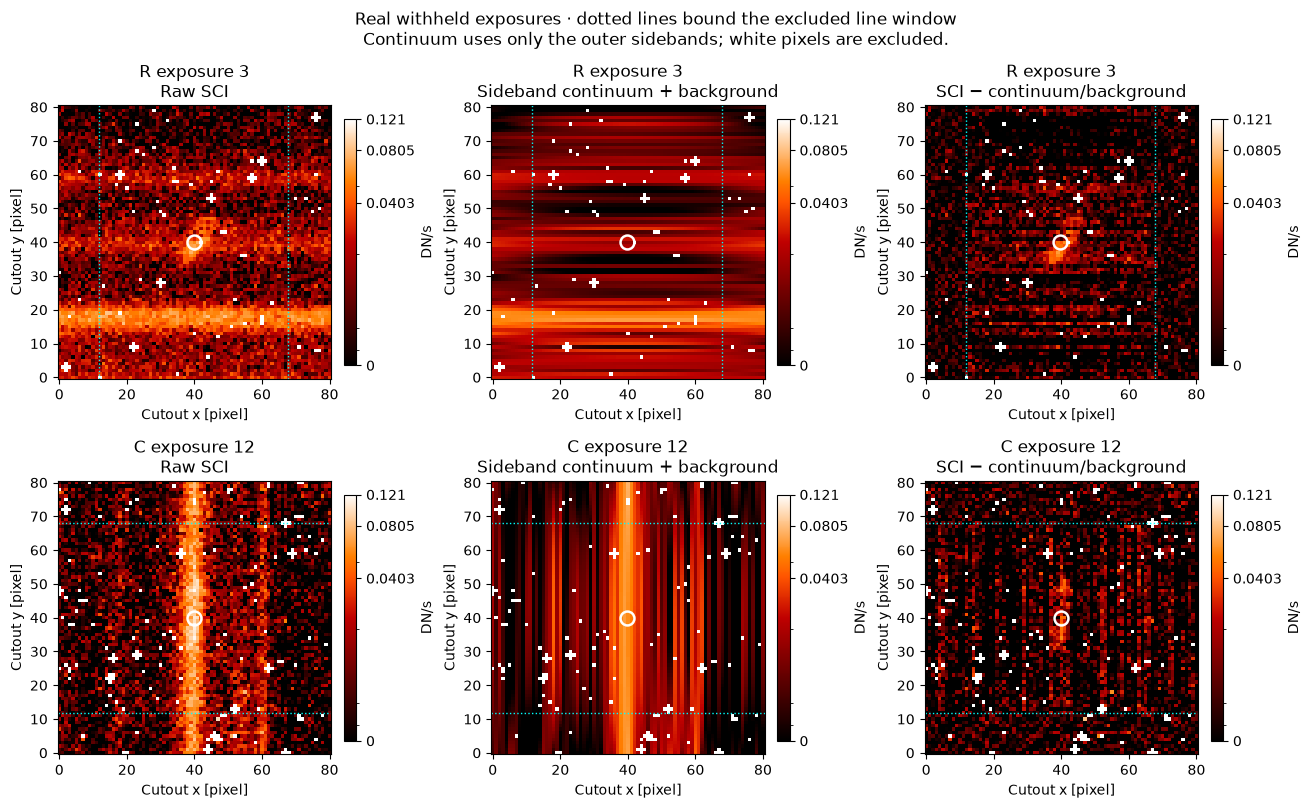

In [3]:
display(review.exposure_table())
show(review.input_figure(r=R_EXPOSURE, c=C_EXPOSURE))

## 3. What did each starting solution find?

`Vrot` is **deprojected rotation at the stated radius**, not the asymptotic speed. `V sin(i)` is the projected amplitude at that radius. The table shows all four starts, including independent smooth-map starts at 200 and 800 km/s.

A smaller training objective is better under this model. An optimizer passing its stationarity check does not establish that its solution is physically trustworthy. **Check the boundary flags.**

In [4]:
with pd.option_context("display.max_columns", None, "display.width", 160):
    display(review.candidate_table().round(3))

,start,Vrot at 4254 pc [km/s],V sin(i) [km/s],inclination [deg],turnover [pc],Δ training objective,optimizer stationary,at a bound
0,saved_lower,194.200,182.329,69.863,170.149,0.000,True,turnover radius
1,saved_higher,1000.000,778.374,51.112,1201.877,50.435,True,rotation speed
2,smooth_200,194.201,182.328,69.861,170.149,0.000,True,turnover radius
3,smooth_800,1000.000,778.395,51.114,1201.816,50.435,True,rotation speed


## 4. Lower-speed solution: R and C residuals

Each row shows the real emission image, the frozen prediction and the residual. **Cyan × marks the projected fitted kinematic center; white ○ marks the nominal calibrated line position.**

The R and C predictions differ because the same galaxy is dispersed in different directions. Residuals are divided by the exposure's ERR; this display does not include continuum uncertainty. The later score comparison propagates that uncertainty and its correlations.

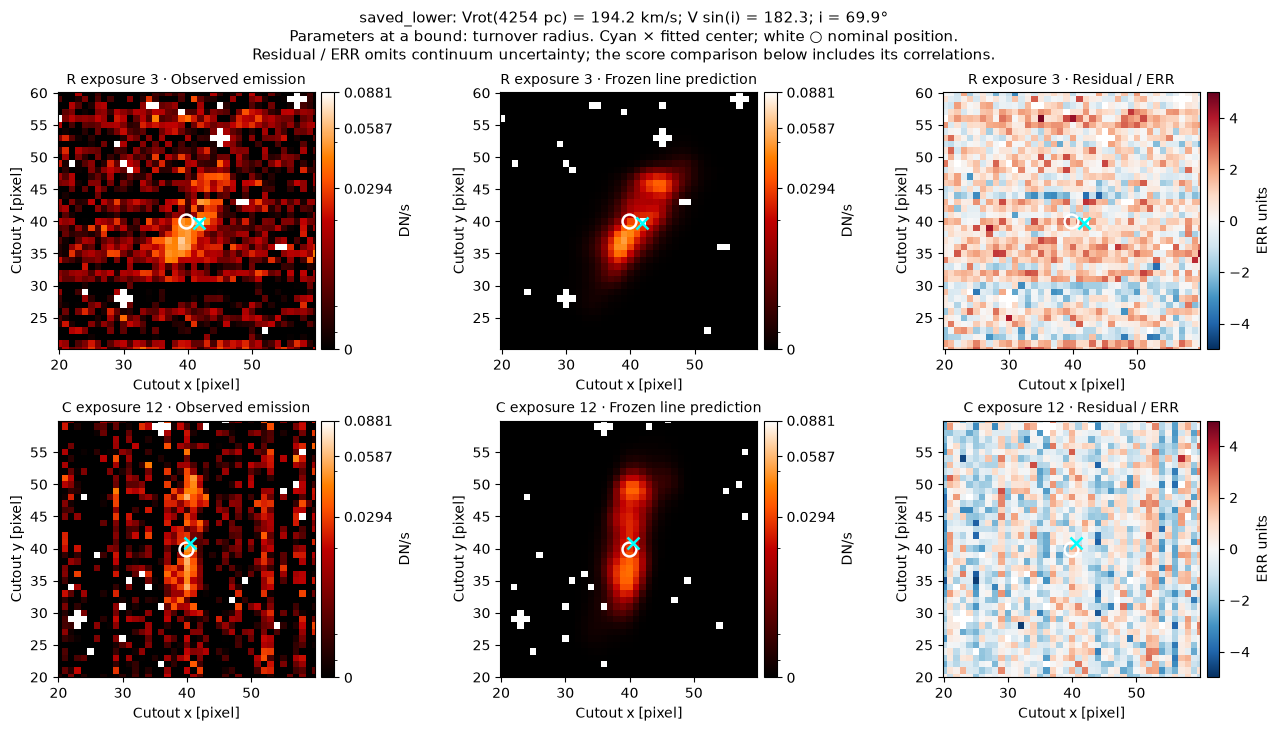

In [5]:
show(review.fit_figure("saved_lower", r=R_EXPOSURE, c=C_EXPOSURE,
    half_width=HALF_WIDTH, residual_limit=RESIDUAL_LIMIT))

## 5. Higher-speed solution: compare the same observations

The same pixels and color scales are used. A velocity at the upper bound is a diagnostic failure flag, not a measured 1000 km/s speed. Look for coherent positive/negative structures around the line, as well as changes in the projected center.

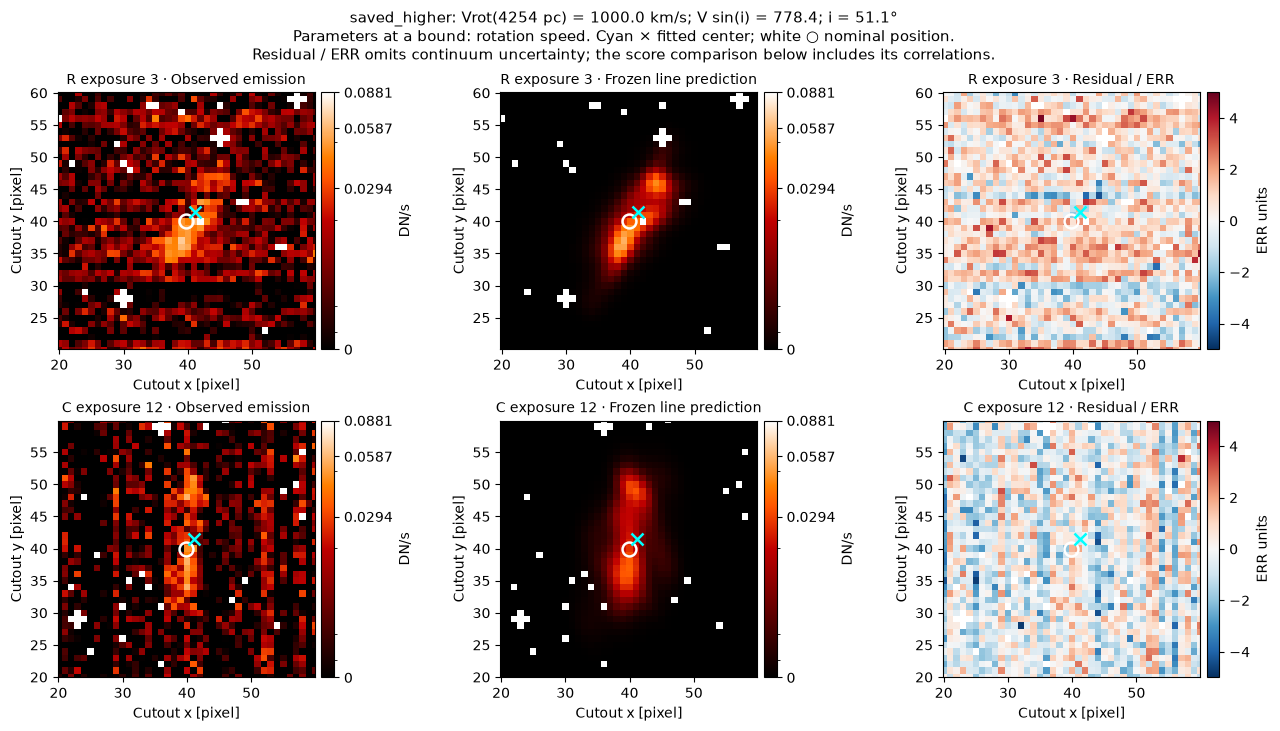

In [6]:
show(review.fit_figure("saved_higher", r=R_EXPOSURE, c=C_EXPOSURE,
    half_width=HALF_WIDTH, residual_limit=RESIDUAL_LIMIT))

# Optional: display every withheld exposure for both solutions.
if SHOW_ALL_EXPOSURES:
    for label in ("saved_lower", "saved_higher"):
        show(review.fit_figure(label, all_exposures=True,
            half_width=HALF_WIDTH, residual_limit=RESIDUAL_LIMIT))

## 6. What galaxy models produced these images?

These are **model maps**, not additional observations. Each solution has one gas-brightness map used for both R and C. Gas brightness need not follow the stellar image. The velocity maps show **line-of-sight rotation relative to systemic velocity**, with a common color scale. The displayed brightness mask is model-defined; it does not establish where the data constrain rotation.

The curves underneath show the assumed arctangent rotation law for each fitted solution. They have no MCMC uncertainty bands. The lower solution's turnover hits its minimum radius, so its inner curve and mass profile remain unresolved.

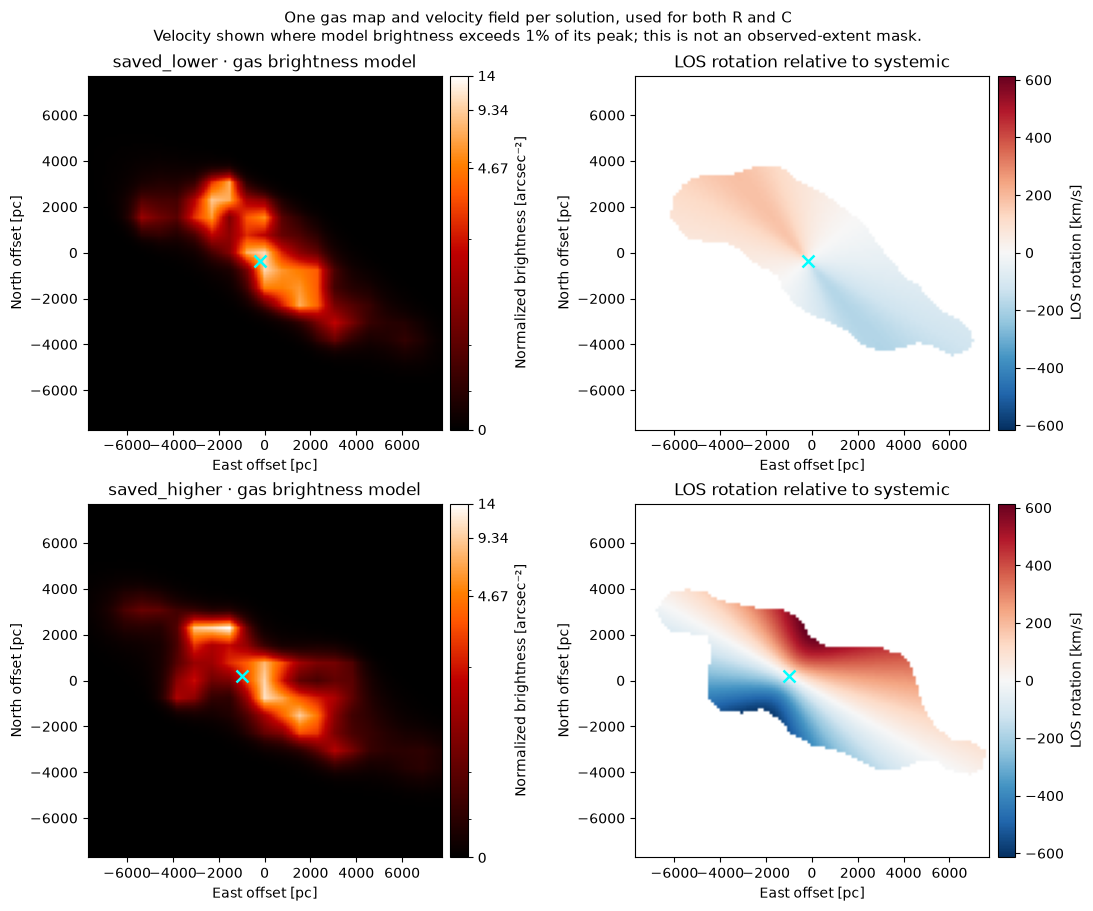

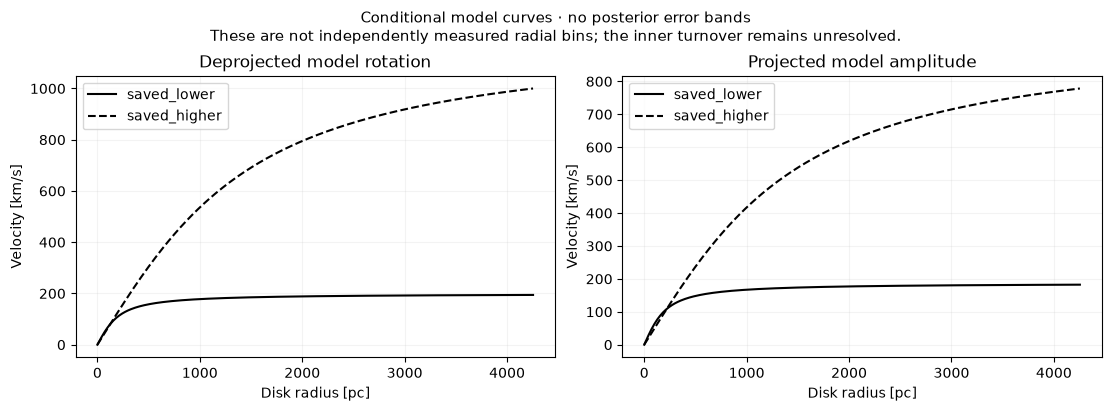

In [7]:
show(review.source_figure())
show(review.rotation_figure())

## 7. Which solution predicts the withheld observations better?

**Positive ΔQ means the higher-speed solution is worse.** The score includes the full correlated continuum uncertainty, conditional on the sideband fit's active coefficients. The table also shows what happens if that uncertainty is omitted.

These are conditional prediction scores, not significance levels or Bayes factors. The per-exposure plot makes disagreements between exposures visible; R and C rows are contributions to the same joint fit, not separate fits.

,region,grism,raw Δχ² (high − low),correlated ΔQ (high − low)
0,line window,all,109.518,34.378
1,line window,R,17.632,27.802
2,line window,C,91.886,6.577
3,core 15 pixels,all,111.692,41.619
4,core 15 pixels,R,19.565,28.763
5,core 15 pixels,C,92.127,12.857


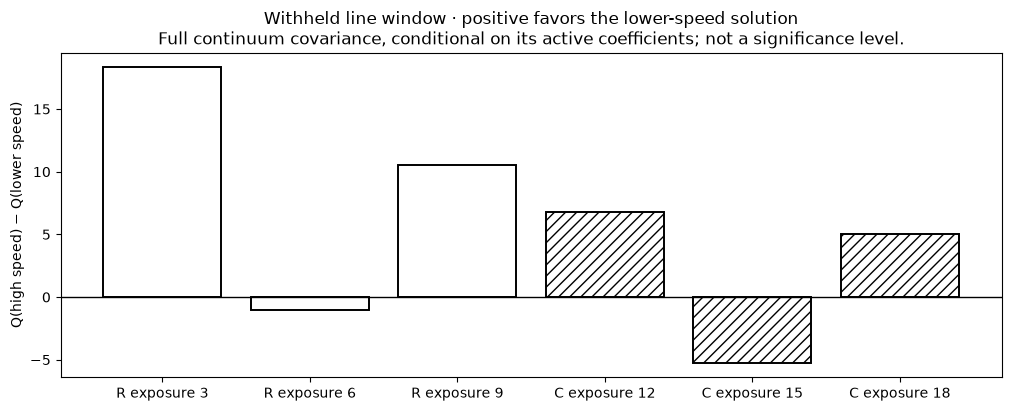

In [8]:
display(review.score_table().round(3))
show(review.score_figure(region="line_window"))  # Alternatively: "core_15_pixels"

## 8. Results and interpretation

The reference experiment favors the lower-speed branch in both grisms, while the higher-speed branch remains a competing local solution. The images are similar enough that visual inspection alone can miss this difference. Continuum-related residual bands and the turnover boundary still limit interpretation.

This is one retrospective exposure split. It does not yet establish MCMC errors, an inner mass profile, or the result for face-on ID15665. This notebook deliberately keeps those limits separate from whether the optimizer finishes.

In [9]:
print(review.notes())
print("\nFinal files:")
for path in sorted(Path(RESULTS_FILE).parent.iterdir()):
    if path.is_file():
        print(" ", path.name)
info = Path(RESULTS_FILE).parent / "run_info.txt"
if info.exists():
    print("\nRun settings and timestamps:", info)
print("Detailed experiment notes:", REPO / "docs" / "real_holdout_ID21636_2026-10-21.md")

Lowest training objective: saved_lower, Vrot = 194.20 km/s at 4254 pc.
Withheld ΔQ (higher − lower) = 34.378; positive favors lower.
This is an optimization/prediction diagnostic, not MCMC. There are no posterior error bars.
Inspect boundary flags and residual structure before interpreting a rotation or mass profile.
Results loaded from: /home/aakavan/kinematics/working/ID21636_validation_2026-10-21/results.npz

Final files:
  higher_velocity_RC.png
  higher_velocity_all_exposures.png
  lower_velocity_RC.png
  lower_velocity_all_exposures.png
  results.npz
  run_info.txt

Run settings and timestamps: /home/aakavan/kinematics/working/ID21636_validation_2026-10-21/run_info.txt
Detailed experiment notes: /home/aakavan/kinematics/grism-kinematics/docs/real_holdout_ID21636_2026-10-21.md
